# キャッサバの病害分類：ResNet-18の最小サンプル

画像の確認 → データ分割 → 学習 → テスト → 誤分類の分析 → 保存した重みで50枚を分類する流れを一巡するノートブックです。
timm の **事前学習なしのResNet-18** を5クラス分類に変更し、ランダムな初期値から学習します。
「動くが、まだ精度が低い」出発点として、前処理も学習量も最低限にした改善練習用のサンプルです。
自作の外部Pythonファイルには依存しません。上から順に実行してください。

## データと環境の準備

[Kaggle: Cassava Leaf Disease Classification](https://www.kaggle.com/competitions/cassava-leaf-disease-classification/data)
のデータを、1-1節でダウンロードできます。手動で取得・展開して次のように配置しても構いません。
初回はKaggleアカウントの認証と、ブラウザでのコンペ規約への同意が必要になる場合があります。

```text
B3CNNpart/
├── Cassava_ResNet18_sample.ipynb
└── data/cassava/
    ├── train.csv                       # image_id, label の2列
    ├── label_num_to_disease_map.json   # ラベル番号と病名の対応
    └── train_images/
        ├── 1000015157.jpg
        └── ...
```

PyTorchとTorchVisionは [公式の手順](https://pytorch.org/get-started/locally/) で対応する組み合わせを入れ、
残りは `python -m pip install -r requirements.txt` で準備します。
事前学習済み重みのダウンロードはありません。NVIDIA GPUがなければCPUを使います。

初期設定は **各クラス最大50枚・64×64・2 epoch** です。画像を縮小し、画素値を0〜1のTensorにするだけです。
少量データ・短時間の学習なので高い精度は期待しませんが、実際の精度は実行して確認してください。


## 1. ライブラリと設定

まず変更するのは `DATA_DIR`、`MAX_PER_CLASS`、`IMAGE_SIZE`、`EPOCHS`、`BATCH_SIZE`、`LR` です。
`MAX_PER_CLASS = None` にすると全画像を使います。結果は実行時刻ごとのフォルダに保存します。
モデルは `MODEL_NAME` で指定します。候補は `timm.list_models("resnet*")` などで確認できます。
モデルを変更する場合は、対応する入力サイズも確認してください。


In [6]:
# パス操作、日時、乱数、時間計測に使う標準ライブラリを読み込みます。
from pathlib import Path
from datetime import datetime
import json
import random
import time

# 数値計算・表データ・画像表示・画像読み込みの道具を読み込みます。
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
# PyTorchと学習に使う部品、画像変換、データ分割・評価指標を読み込みます。
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# ノートブックの場所を基準に、データと出力のルートを決めます。
PROJECT_DIR = Path.cwd() / "B3CNNpart" if (Path.cwd() / "B3CNNpart").is_dir() else Path.cwd()
# 学習画像とCSVの保存場所です。手元の配置に合わせて変更できます。
DATA_DIR = PROJECT_DIR / "data" / "cassava"  # 手元の配置に合わせて変更
# timmで作るモデル名です。ここを変更すると別のモデルを試せます。
MODEL_NAME = "resnet18"
# 実行ごとの結果保存先です。時刻を付けて過去の実験と分けます。
OUTPUT_DIR = PROJECT_DIR / "outputs" / f"cassava_{MODEL_NAME}" / datetime.now().strftime("%Y%m%d_%H%M%S")
# 乱数の種を固定し、分割や初期値を再現しやすくします。
SEED = 42
MAX_PER_CLASS = 50  # 分割前の各クラスの上限。Noneなら全画像
# 学習前に画像を縮小する一辺の長さです。大きくすると計算量も増えます。
IMAGE_SIZE = 64
EPOCHS = 2  # まずは短い学習で動作を確認
# 1回の重み更新で同時に見る画像数です。GPUメモリに合わせて調整します。
BATCH_SIZE = 32
# 学習率です。重みを1回の更新でどれだけ動かすかを決めます。
LR = 1e-4

# Python・NumPy・PyTorchの乱数をそろえる関数です。
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 学習前の乱数を固定し、同じ設定で比較しやすくします。
set_seed(SEED)
# GPUが使えればGPU、なければCPUを選びます。
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("data:", DATA_DIR.resolve())
print("output:", OUTPUT_DIR.resolve())


device: cuda
data: /workspace/B3CNNpart/data/cassava
output: /workspace/B3CNNpart/outputs/cassava_resnet18/20261021_051557


### 1-1. Kaggleからデータをダウンロードする

この作業はデータセットをCLI上で取得するためのコードです．普通にダウンロードして解凍するほうが楽だと思うのでそっちでもいいです．

データがまだない場合は、下のセルで `kagglehub.competition_download()` を実行します。
保存先は `DATA_DIR`（初期値は `data/cassava/`）です。Dockerでもホスト側に残ります。
学習で使う250枚だけでなく**コンペのデータ全体**を取得するので、初回は時間とディスク容量が必要です。
配置済みならダウンロードをスキップします。

初回の準備：
1. [コンペページ](https://www.kaggle.com/competitions/cassava-leaf-disease-classification/rules)でログインし、規約を確認して同意します。この操作はブラウザで本人が行います。
2. 認証が必要なら、認証セルを `KAGGLE_LOGIN = True` にして単独で実行します。
   [Kaggleの設定](https://www.kaggle.com/settings/api)で生成したAPIトークンを、表示される **API Token** 欄に入力し、**Login** を押してください。
   トークンをコードやチャットに貼り付ける必要はありません。
3. ダウンロードセルを実行する前に、ブラウザで [コンペの規約ページ](https://www.kaggle.com/competitions/cassava-leaf-disease-classification/rules)を開き、**Late Submission** をクリックしてください。規約への同意画面が表示されたら、内容を確認して同意します。この操作を済ませ、認証成功を確認してから、次のダウンロードセルを実行します。ログイン画面は入力を待たずにセルが終了するため、初回は「すべて実行」を使わず順に操作してください。
4. ダウンロード完了後、そのまま2節以降を実行します。

`ModuleNotFoundError: kagglehub` が出る環境では、別セルで `%pip install kagglehub==1.0.2` を実行してください。
この教材のDocker環境には追加済みです。認証情報はコンテナ再作成時に再入力が必要になる場合があります。
参考：[kagglehub公式の認証・ダウンロード手順](https://github.com/Kaggle/kagglehub)。


In [7]:
# 初回や認証エラー時はTrueにして、このセルだけを実行します。
# 初回など認証が必要な場合だけTrueにし、Kaggleへログインします。
KAGGLE_LOGIN = False
if KAGGLE_LOGIN:
    import kagglehub
    kagglehub.login()
    print("API Token欄にトークンを入力してLoginを押し、認証成功後に次のセルを実行してください。")


In [8]:
# 認証が必要ならTrueにして上のログインセルを実行します。
KAGGLE_LOGIN = False # 初回や認証エラー時はTrueにして再実行

# 必要なCSV・ラベル対応表・画像がそろっているか確認します。
def cassava_data_ready(directory):
    if not (directory / "train.csv").is_file():
        return False
    if not (directory / "label_num_to_disease_map.json").is_file():
        return False
    if not (directory / "train_images").is_dir():
        return False
    frame = pd.read_csv(directory / "train.csv")
    return (not frame.empty and "image_id" in frame.columns
            and all((directory / "train_images" / name).is_file() for name in frame["image_id"]))

# データがそろっていれば再ダウンロードせず、そのまま利用します。
if cassava_data_ready(DATA_DIR):
    print("配置済みのデータを使います:", DATA_DIR.resolve())
# データがない場合はKaggleからコンペデータを取得します。
else:
    import kagglehub

    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    print("コンペのデータ全体をダウンロードします。保存先:", DATA_DIR.resolve())
    # 認証や通信の失敗時に、原因確認の手がかりを表示します。
    try:
        path = kagglehub.competition_download(
            "cassava-leaf-disease-classification", output_dir=str(DATA_DIR.resolve())
        )
    except Exception:
        print("取得に失敗しました。下のエラー詳細を確認してください。")
        print("401/403や認証エラー: コンペ規約への同意とAPIトークンを確認し、")
        print("上の認証セルでログインを完了してから、このセルを再実行してください。")
        print("通信・容量のエラー: 接続や空き容量を確認して再実行してください。")
        raise
    DATA_DIR = Path(path)
    if not cassava_data_ready(DATA_DIR):
        raise FileNotFoundError(f"取得先にCSV・ラベルJSON・学習画像が揃っていません: {DATA_DIR}")
    print("準備完了:", DATA_DIR.resolve())


配置済みのデータを使います: /workspace/B3CNNpart/data/cassava


## 2. CSVを読み、クラス数と画像を確認する

病名の対応は付属のJSONから読みます。まず元データのクラス別枚数を確認します。
サンプルでは各クラス最大50枚に絞るため、後の評価値は元データ全体のクラス比率とは異なる場合があります。


                               disease  original_count
0       Cassava Bacterial Blight (CBB)            1087
1  Cassava Brown Streak Disease (CBSD)            2189
2           Cassava Green Mottle (CGM)            2386
3         Cassava Mosaic Disease (CMD)           13158
4                              Healthy            2577


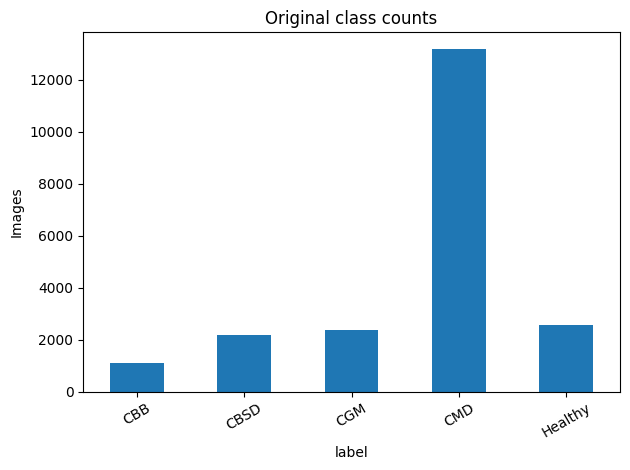

今回使う枚数: 250


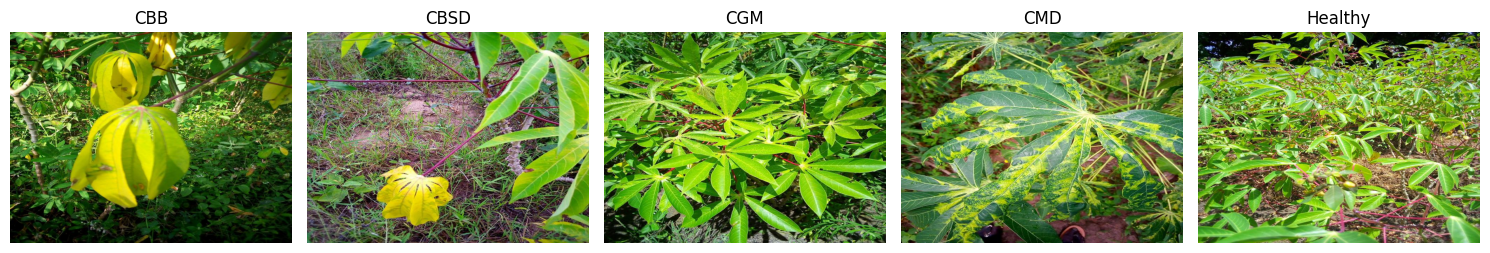

In [9]:
# 学習に必要な3つのファイル・フォルダがあるか調べます。
required = [DATA_DIR / "train.csv", DATA_DIR / "label_num_to_disease_map.json", DATA_DIR / "train_images"]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("データを配置するかDATA_DIRを変更してください:\n" + "\n".join(missing))

# CSVを表として読み込み、画像ファイル名と正解ラベルを取得します。
df = pd.read_csv(DATA_DIR / "train.csv")
# 必須列、欠損、重複、5クラスの番号が正しいか検査します。
assert {"image_id", "label"}.issubset(df.columns), "CSVにはimage_id列とlabel列が必要です"
assert df[["image_id", "label"]].notna().all().all(), "画像名・ラベルに欠損があります"
assert df["image_id"].is_unique, "CSVに重複する画像名があります"
# 数字ラベルと病名の対応をJSONから読み込みます。
label_map = json.loads((DATA_DIR / "label_num_to_disease_map.json").read_text(encoding="utf-8"))
num_classes = len(label_map)
assert num_classes == 5 and set(map(int, label_map)) == set(range(5)), "0～4の5クラスを想定しています"
assert set(df["label"]) == set(range(num_classes)), "CSVとJSONのラベルが一致しません"
df["label"] = df["label"].astype(int)
# ラベル番号の順に病名を並べ、図や表示で使います。
class_names = [label_map[str(i)] for i in range(num_classes)]
short_names = [name.split("(")[-1].rstrip(")") if "(" in name else name for name in class_names]

# 元データのクラス別枚数を集計し、偏りを図で確認します。
counts = df["label"].value_counts().sort_index()
print(pd.DataFrame({"disease": class_names, "original_count": counts.to_numpy()}))
counts.rename(index=dict(enumerate(short_names))).plot.bar(title="Original class counts", rot=30)
plt.ylabel("Images")
plt.tight_layout()
plt.show()

# 動作確認を速くするため、各クラスから上限枚数だけ抽出します。
if MAX_PER_CLASS is not None:
    df = pd.concat([
        group.sample(n=min(MAX_PER_CLASS, len(group)), random_state=SEED)
        for _, group in df.groupby("label")
    ], ignore_index=True)
# 行番号を振り直し、各クラスに最低限の画像があるか確認します。
df = df.reset_index(drop=True)
assert df["label"].value_counts().min() >= 10, "各クラス最低10枚以上を用意してください"
# CSVにある名前の画像がすべて存在するか調べます。
missing_images = [name for name in df["image_id"] if not (DATA_DIR / "train_images" / name).is_file()]
if missing_images:
    raise FileNotFoundError(f"画像が見つかりません（先頭5件）: {missing_images[:5]}")
print("今回使う枚数:", len(df))

# 各クラスから1枚ずつ表示し、画像とラベルを目で確認します。
fig, axes = plt.subplots(1, num_classes, figsize=(15, 3))
for label, ax in enumerate(axes):
    row = df[df["label"] == label].iloc[0]
    with Image.open(DATA_DIR / "train_images" / row["image_id"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(short_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. 学習60%・検証20%・テスト20%に分ける

クラスの割合を保つ層化分割を使います。学習は重みの更新、検証は学習状況の確認、
テストは最後の評価に使います。Kaggleのラベルなしtest画像ではなく、ラベル付きtrain画像の一部をテスト用に確保します。

ここでは画像単位の分割です。同じ株や連写画像の情報がある場合は、発展時に株・撮影単位で分割してください。
初期設定の250枚では学習150枚・検証50枚・テスト50枚です。9節ではテスト画像を分類演習用にコピーします。


In [10]:
# ラベルの割合を保って、まず60%を学習用、40%を残りに分けます。
train_df, rest_df = train_test_split(df, test_size=0.40, stratify=df["label"], random_state=SEED)
# 残りを半分に分け、検証用20%とテスト用20%を作ります。
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df["label"], random_state=SEED)
train_df, val_df, test_df = [part.reset_index(drop=True) for part in (train_df, val_df, test_df)]
# 同じ画像が複数の分割に混ざっていないことを確認します。
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(train_df.image_id).isdisjoint(test_df.image_id)
assert set(val_df.image_id).isdisjoint(test_df.image_id)

# 分割ごとのクラス枚数を表示し、偏りを確認します。
split_counts = pd.DataFrame({
    name: part["label"].value_counts().sort_index()
    for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]
})
split_counts.index = short_names
print(split_counts)

# 出力フォルダを作り、後から同じ分割を再現できるようCSV保存します。
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.concat([part.assign(split=name) for name, part in [
    ("train", train_df), ("val", val_df), ("test", test_df)
]]).to_csv(OUTPUT_DIR / "splits.csv", index=False)


         train  val  test
CBB         30   10    10
CBSD        30   10    10
CGM         30   10    10
CMD         30   10    10
Healthy     30   10    10


## 4. 画像の前処理とDataLoader

RGBに変換した画像を64×64にリサイズし、`ToTensor()`で画素値を0〜1にします。
学習・検証・テストで同じ前処理を使い、画像拡張や平均・標準偏差による正規化は行いません。
縦横比もそのままではなく正方形に変形します。`num_workers=0` はNotebookで扱いやすい設定です。


In [11]:
# 画像を同じ大きさにし、PyTorch用Tensor（画素値0〜1）へ変換します。
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

# 画像を1枚ずつ読み込み、変換後の画像と正解ラベルを返すクラスです。
class CassavaDataset(Dataset):
    # 画像一覧と前処理方法をDatasetに記録します。
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    # Datasetに含まれる画像枚数を返します。
    def __len__(self):
        return len(self.frame)

    # 指定された行の画像を開き、RGB化・変換してラベルと一緒に返します。
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(DATA_DIR / "train_images" / row["image_id"]) as image:
            image = image.convert("RGB")
        return self.transform(image), int(row["label"])

# Datasetを小分けのバッチにして学習・評価へ渡す準備をします。
def make_loader(frame, transform, shuffle=False):
    return DataLoader(CassavaDataset(frame, transform), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

# 検証・テストでは順番を保ち、予測と画像の対応を維持します。
val_loader = make_loader(val_df, transform)
test_loader = make_loader(test_df, transform)  # 予測と画像名の対応を保つためshuffleしない


## 5. ResNet-18を学習する

`timm.create_model(MODEL_NAME, pretrained=False, num_classes=num_classes)` で、
事前学習済み重みを使わない5クラス分類モデルを作ります。
参考：[timm公式ガイド](https://huggingface.co/docs/timm/quickstart)。
損失は交差エントロピー、最適化はAdam（学習率0.0001）、バッチサイズ32です。
2 epochだけ全層を学習し、最後のepochの重みをそのまま使います。
検証結果は学習状況の確認に使います。このセルを再実行すると最初から学習します。


In [ ]:
# 1周分の学習または評価を行い、平均損失と正解率を返します。
def run_epoch(loader, optimizer=None):
    # optimizerがあるときだけ学習モードにします。
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, count = 0.0, 0, 0
    # バッチを取り出して、画像と正解をCPU/GPUへ移します。
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        # 学習時は前回の勾配を消してから計算します。
        if training:
            optimizer.zero_grad()
        # 学習時だけ勾配を記録し、評価時は計算を軽くします。
        with torch.set_grad_enabled(training):
            # モデルが各クラスらしさ（スコア）を計算します。
            logits = model(images)
            # 予測と正解のずれを損失として計算します。
            loss = criterion(logits, labels)
            # 学習時は誤差を逆伝播し、最適化手法で重みを更新します。
            if training:
                loss.backward()
                optimizer.step()
        # バッチの損失・正解数を足し、全データ平均を出せるようにします。
        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += labels.size(0)
    # 1周分の平均損失と正解率を返します。
    return loss_sum / count, correct / count

# モデル初期値を含む学習の乱数を固定します。
set_seed(SEED)
# 学習データだけ順番をシャッフルしながらバッチ化します。
train_loader = make_loader(train_df, transform, shuffle=True)
# 指定したモデルを5クラス分類用に作成し、選択した装置へ載せます。
model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=num_classes).to(device)
# 多クラス分類で使う交差エントロピー損失を設定します。
criterion = nn.CrossEntropyLoss()
# Adamでモデルの重みを更新します。LRは学習率です。
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = []
assert EPOCHS >= 1, "EPOCHSは1以上にしてください"

# 指定した回数だけ、学習データと検証データを順に評価します。
for epoch in range(1, EPOCHS + 1):
    # 1 epochにかかった時間を測り始めます。
    started = time.perf_counter()
    # 学習と検証それぞれの損失・正解率を計算します。
    train_loss, train_acc = run_epoch(train_loader, optimizer)
    val_loss, val_acc = run_epoch(val_loader)
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        train_accuracy=train_acc, val_accuracy=val_acc))
    print(f"{epoch:2d}/{EPOCHS}  loss={train_loss:.4f}/{val_loss:.4f}  "
          f"accuracy={train_acc:.3f}/{val_acc:.3f}  {time.perf_counter()-started:.1f}s")

# 学習経過を表にして、後からグラフ化できるようCSV保存します。
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)


## 6. 学習曲線を見る

学習損失だけ下がって検証損失が上がる場合は、過学習の可能性があります。
両方の損失が下がらない場合は、画像・ラベル・学習率・epoch数を確認します。


In [ ]:
# 学習・検証の損失と正解率を並べて比較する図を作ります。
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
# trainとvalの値をそれぞれのグラフに線で描きます。
for split in ["train", "val"]:
    axes[0].plot(history_df.epoch, history_df[f"{split}_loss"], label=split, marker="o")
    axes[1].plot(history_df.epoch, history_df[f"{split}_accuracy"], label=split, marker="o")
# 軸の名前や凡例、補助線を整えて図として保存・表示します。
for ax, title in zip(axes, ["Loss", "Accuracy"]):
    ax.set(xlabel="Epoch", title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
plt.show()


## 7. テストの正解率・クラス別指標・混同行列

Accuracyは全体の正解率、macro F1は各クラスのF1を均等に平均した値です。
Precisionは「そのクラスと予測した中の正解割合」、Recallは「そのクラスの画像を見つけられた割合」です。
5クラスを一様にランダムに予測する場合の期待Accuracyは20%です。実際の評価ではクラス別指標も確認します。
混同行列は縦が正解、横が予測です。対角線以外の大きな値から、混同しやすい病害を探します。


In [ ]:
# モデルを評価モードにし、学習時専用の動作を止めます。
model.eval()
# 各テスト画像について、5クラスそれぞれの確率を集めます。
probabilities = []
# 評価では勾配を計算せず、メモリと時間を節約します。
with torch.inference_mode():
    for images, _ in test_loader:
        probabilities.append(model(images.to(device)).softmax(dim=1).cpu().numpy())
probabilities = np.concatenate(probabilities)
# テストデータの正解ラベルを取り出します。
y_true = test_df["label"].to_numpy()
# 確率が最も高いクラスを予測ラベルにします。
y_pred = probabilities.argmax(axis=1)
# 全体の正解率と、クラスを均等に扱うMacro F1を計算します。
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, labels=list(range(num_classes)), average="macro", zero_division=0)
print(f"Test accuracy: {accuracy:.4f}  /  Macro F1: {macro_f1:.4f}")
# クラスごとの適合率・再現率・F1をまとめます。
report = classification_report(y_true, y_pred, labels=list(range(num_classes)),
                               target_names=short_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame({key: value for key, value in report.items() if isinstance(value, dict)}).T
print(report_df.round(3))
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

# 正解と予測の組み合わせを混同行列にして保存します。
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(num_classes)),
                                       display_labels=short_names, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Test confusion matrix")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

# 画像名・正解・予測・確信度を一つの表にまとめます。
results = test_df.copy()
results["prediction"] = y_pred
results["confidence"] = probabilities.max(axis=1)
results["correct"] = y_true == y_pred
# 各クラスの予測確率も列に加え、CSVに保存します。
for label in range(num_classes):
    results[f"prob_{label}"] = probabilities[:, label]
results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)


## 8. 誤分類画像を確認する

予測スコアが高いのに間違えた画像を最大9枚表示します。スコアはsoftmaxの値であり、正しさの保証ではありません。
葉の位置・病斑・背景・暗さ・複数の葉などを観察します。表示する画像はリサイズ前の元画像です。


In [ ]:
# 間違えた画像を確信度の高い順に最大9枚選びます。
errors = results[~results["correct"]].sort_values("confidence", ascending=False).head(9)
# 間違いがなければそのことを表示します。
if errors.empty:
    print("このテスト分割では誤分類がありませんでした。")
# 誤分類があれば画像と正解・予測を並べて確認します。
else:
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, errors.iterrows()):
        with Image.open(DATA_DIR / "train_images" / row["image_id"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"True: {short_names[int(row['label'])]}\n"
                     f"Pred: {short_names[int(row['prediction'])]} ({row['confidence']:.2f})")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "misclassified.png", dpi=150)
    plt.show()


## 9. 保存した重みで50枚をまとめて分類する

学習と、学習済み重みを使う「推論」を分けて体験します。
まず最後のepochの重みと、学習・検証に使っていないテスト画像を最大50枚保存します。
初期設定では各クラス10枚、合計50枚です。テスト画像が50枚未満なら全枚を使います。

続く「9-2」は、上から順に実行した場合は今回の保存先を自動で使います。
カーネルを再起動した場合は、`RUN_DIR`を9-1で表示された保存先に設定すれば実行できます。
保存した重みから新しくモデルを作り、画像フォルダを分類して予測CSVと一覧画像を出力します。
正解CSVは分類後の答え合わせにだけ使います。7節と同じテスト画像なので、独立した追加評価ではありません。

### 9-1. 重みと分類演習用データを保存する


In [ ]:
# モデルの学習済み重みをCPU上の辞書に移します。
state = {name: value.detach().cpu() for name, value in model.state_dict().items()}
# 重みと推論に必要なモデル名・病名・前処理条件を保存します。
torch.save({"model_state_dict": state, "class_names": class_names,
            "architecture": MODEL_NAME, "timm_version": str(timm.__version__), "epoch": EPOCHS,
            "preprocessing": {"color_mode": "RGB", "input_size": IMAGE_SIZE,
                              "resize": "square", "to_tensor": True, "normalize": False}},
           OUTPUT_DIR / "cassava_model.pth")
# 学習条件、データ枚数、テスト成績を記録する辞書を作ります。
summary = {
    "architecture": MODEL_NAME, "timm_version": str(timm.__version__),
    "seed": SEED, "max_per_class": MAX_PER_CLASS, "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "learning_rate": LR, "input_size": IMAGE_SIZE,
    "optimizer": "Adam", "pretrained": False, "epoch": EPOCHS,
    "weight_selection": "last_epoch", "augmentation": False, "normalize": False, "class_names": class_names,
    "data_dir": str(DATA_DIR.resolve()), "device": str(device), "torch_version": str(torch.__version__),
    "sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "test_accuracy": float(accuracy), "test_macro_f1": float(macro_f1),
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("保存先:", OUTPUT_DIR.resolve())

# 正解ラベルは画像フォルダと分け、分類時には読みません。
import shutil
# テスト画像から、推論演習に使う画像と正解を準備します。
exercise_df = test_df.copy()
# 50枚を超えるときはクラス比率を保った50枚に絞ります。
if len(exercise_df) > 50:
    exercise_df, _ = train_test_split(exercise_df, train_size=50,
                                    stratify=exercise_df["label"], random_state=SEED)
# 正解を見ずに分類できるよう、演習画像専用フォルダを作ります。
exercise_dir = OUTPUT_DIR / "inference_images"
exercise_dir.mkdir(exist_ok=True)
# 再実行時も同じフォルダへ同じ画像をコピーします。
# 選んだ画像を演習フォルダへコピーし、正解は別CSVに保存します。
for image_id in exercise_df["image_id"]:
    shutil.copy2(DATA_DIR / "train_images" / image_id, exercise_dir / image_id)
exercise_df[["image_id", "label"]].to_csv(OUTPUT_DIR / "inference_answers.csv", index=False)
print("分類演習用の画像:", len(exercise_df))
print(f'次のセルの設定: RUN_DIR = Path({str(OUTPUT_DIR.resolve())!r})')


### 9-2. 保存した重みを読み込み、画像フォルダを分類する

9-1まで順に実行した場合は、設定を変えずに実行できます。
このセルだけを実行する場合や過去の重みを使う場合は、`RUN_DIR = None` を
`RUN_DIR = Path("9-1で表示された保存先の絶対パス")` に書き換えてください。


In [ ]:
# このセル単独でも動くよう、推論に必要なライブラリを読み込みます。
from pathlib import Path
import torch
import timm
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# Noneなら今回のOUTPUT_DIRを使用。過去の重みを使う場合はPath("保存先")を指定します。
# Noneなら直前の学習結果を使います。別の重みなら保存先を指定します。
RUN_DIR = None
# 学習セルの保存先を取得し、未実行なら案内して止めます。
if RUN_DIR is None:
    RUN_DIR = globals().get("OUTPUT_DIR")
    if RUN_DIR is None:
        raise ValueError("RUN_DIRに9-1で表示された保存先をPathで指定してください。上から実行する場合は先に9-1まで完了してください。")
RUN_DIR = Path(RUN_DIR)
# 重みと画像フォルダがあることを先に確認します。
if not (RUN_DIR / "cassava_model.pth").is_file():
    raise FileNotFoundError(
        f"保存済みの重みがありません: {RUN_DIR.resolve() / 'cassava_model.pth'}\n"
        "先に9-1の保存セルを実行してください。過去の重みを使う場合はRUN_DIRをその保存先に変更してください。"
    )
INFERENCE_DIR = RUN_DIR / "inference_images"
if not INFERENCE_DIR.is_dir():
    raise FileNotFoundError(f"分類用画像フォルダがありません: {INFERENCE_DIR.resolve()}。9-1を完了するか、INFERENCE_DIRを画像のあるフォルダに変更してください。")
print("読み込む保存先:", RUN_DIR.resolve())
# 推論に使うGPUまたはCPUを選びます。
inference_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# 保存した重みと設定を読み込みます。
checkpoint = torch.load(RUN_DIR / "cassava_model.pth", map_location="cpu", weights_only=True)
# 数字ラベルを病名に変換する一覧を復元します。
inference_names = checkpoint["class_names"]
# 保存時と同じ構造のモデルを作り、重みを読み込みます。
inference_model = timm.create_model(checkpoint["architecture"], pretrained=False,
                                    num_classes=len(inference_names))
inference_model.load_state_dict(checkpoint["model_state_dict"])
inference_model.to(inference_device).eval()
# 学習時に使った画像サイズを重みファイルから取得します。
size = checkpoint["preprocessing"]["input_size"]
inference_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
])
# 指定フォルダ内の対応画像を並べて取得します。
image_paths = sorted(path for path in INFERENCE_DIR.iterdir()
                     if path.suffix.lower() in {".jpg", ".jpeg", ".png"})
if not image_paths:
    raise ValueError(f"分類する画像がありません: {INFERENCE_DIR}")

# 画像ごとの予測結果をこのリストに集めます。
rows = []
# 推論では勾配計算を止め、画像をまとめて分類します。
with torch.inference_mode():
    for start in range(0, len(image_paths), 32):
        batch_paths = image_paths[start:start + 32]
        images = []
        for path in batch_paths:
            with Image.open(path) as image:
                images.append(inference_transform(image.convert("RGB")))
        scores = inference_model(torch.stack(images).to(inference_device)).softmax(dim=1).cpu()
        for path, score in zip(batch_paths, scores):
            prediction = int(score.argmax())
            rows.append({"image_id": path.name, "prediction": prediction,
                         "disease": inference_names[prediction], "confidence": float(score.max())})
# 結果を表にしてCSVへ保存し、画面にも表示します。
predictions = pd.DataFrame(rows)
predictions.to_csv(RUN_DIR / "inference_predictions.csv", index=False)
print(predictions.to_string(index=False))

# 全画像を10枚ずつ表示して、予測した病名を確認します。
for start in range(0, len(image_paths), 10):
    fig, axes = plt.subplots(2, 5, figsize=(16, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, path, row in zip(axes.flat, image_paths[start:start + 10], rows[start:start + 10]):
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        name = row["disease"]
        short = name.split("(")[-1].rstrip(")") if "(" in name else name
        ax.set_title(f"{path.name}\n{short} ({row['confidence']:.2f})", fontsize=9)
    plt.tight_layout()
    fig.savefig(RUN_DIR / f"inference_gallery_{start // 10 + 1}.png", dpi=150)
    plt.show()

# 分類が終わってから正解と照合します（正解CSVがない画像フォルダでも分類可能）。
# 演習用の正解CSVがある場合だけ、最後に答え合わせします。
answer_path = RUN_DIR / "inference_answers.csv"
if answer_path.exists():
    answers = pd.read_csv(answer_path)
    checked = predictions.merge(answers, on="image_id", validate="one_to_one")
    if len(checked):
        checked["correct"] = checked["prediction"] == checked["label"]
        checked.to_csv(RUN_DIR / "inference_checked.csv", index=False)
        print(f"答え合わせ: {checked['correct'].sum()} / {len(checked)} 枚正解")


## 次に試すこと

初期設定は、少量の小さな画像で短く学習するだけの出発点です。
一度に多くを変更せず、同じデータ分割・seedで検証結果を比べてください。

1. `EPOCHS`を2から10などに増やし、学習・検証の損失がどう変わるかを見る。
2. `IMAGE_SIZE`を64から128などに増やし、病斑の細かい情報が性能に影響するか調べる。
3. 学習画像だけに左右反転などの画像拡張を追加する。
4. 事前学習済み重みと、その重みに対応した入力サイズ・正規化を導入する。
5. 学習データを増やす。比較時は検証・テスト画像を固定し、学習画像との重複を避ける。
   `MAX_PER_CLASS`を変えて分割からやり直すと、seedが同じでも評価画像は変わります。

テスト結果を見て繰り返し調整すると、テストが最終評価として使えなくなります。
調整は検証データで行い、テストは比較する設定を決めてから評価してください。
